# IELTS Practice Analytics and Machine Learning

This notebook reads `ielts_platform_pro.db` without modifying it. It analyzes attempt and per-part AI-estimated bands, skill/theme patterns, rubric criterion scores, strengths/weaknesses, and generation QA reports.

> Scores are AI practice estimates, not official IELTS results. Speaking pronunciation is not scoreable from the app's text-only response. Older attempts have no criterion rows and older tests have no QA rows, so criterion and QA summaries will initially cover only new records. Text keyword analysis is exploratory, not a validated criterion score. Predictive models learn historical AI estimates unless human-reviewed labels are separately collected.

In [15]:
from pathlib import Path
import ast
import re
import sqlite3
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 30)

def find_database(start: Path = Path.cwd()) -> Path:
    for directory in (start.resolve(), *start.resolve().parents):
        candidate = directory / 'ielts_platform_pro.db'
        if candidate.is_file():
            return candidate
    raise FileNotFoundError('Could not find ielts_platform_pro.db. Run this notebook from the project or a child folder.')

DB_PATH = find_database()
print(f'Read-only analytics source: {DB_PATH}')

Read-only analytics source: D:\MindX\CSI\FINAL-PROJECT-CSI\ielts_platform_pro.db


In [16]:
with sqlite3.connect(f'file:{DB_PATH.as_posix()}?mode=ro', uri=True) as connection:
    table_names = {row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type='table'")}
    required_tables = {'tests', 'submissions', 'submission_parts'}
    missing_tables = required_tables - table_names
    if missing_tables:
        raise RuntimeError(f'Missing expected tables: {sorted(missing_tables)}')

    attempts_df = pd.read_sql_query('''
        SELECT s.submission_id, s.test_id, s.timestamp, s.graded_band, s.feedback,
               s.user_responses, t.skill_type, t.theme, t.target_band
        FROM submissions AS s
        JOIN tests AS t ON t.test_id = s.test_id
        ORDER BY s.timestamp
    ''', connection)
    parts_df = pd.read_sql_query('''
        SELECT sp.submission_id, sp.test_id, sp.part_number, sp.band_score,
               sp.strengths, sp.weaknesses, sp.feedback AS part_feedback,
               s.timestamp, s.user_responses, t.skill_type, t.theme, t.target_band
        FROM submission_parts AS sp
        JOIN submissions AS s ON s.submission_id = sp.submission_id
        JOIN tests AS t ON t.test_id = sp.test_id
        ORDER BY s.timestamp, sp.part_number
    ''', connection)
    if 'submission_criteria' in table_names:
        criteria_df = pd.read_sql_query('''
            SELECT sc.submission_id, sc.test_id, sc.part_number, sc.criterion_name,
                   sc.band_score, sc.evidence, s.timestamp, t.skill_type, t.theme, t.target_band
            FROM submission_criteria AS sc
            JOIN submissions AS s ON s.submission_id = sc.submission_id
            JOIN tests AS t ON t.test_id = sc.test_id
            ORDER BY s.timestamp, sc.part_number, sc.criterion_name
        ''', connection)
    else:
        criteria_df = pd.DataFrame(columns=['submission_id', 'test_id', 'part_number', 'criterion_name', 'band_score', 'evidence', 'timestamp', 'skill_type', 'theme', 'target_band'])
    if 'exam_quality' in table_names:
        quality_df = pd.read_sql_query('''
            SELECT q.*, t.skill_type, t.theme
            FROM exam_quality AS q
            JOIN tests AS t ON t.test_id = q.test_id
            ORDER BY q.validated_at
        ''', connection)
    else:
        quality_df = pd.DataFrame(columns=['test_id', 'target_band', 'estimated_band', 'difficulty_fit', 'answer_key_status', 'quality_passed', 'issues', 'summary', 'validated_at', 'skill_type', 'theme'])
    if 'human_ratings' in table_names:
        human_ratings_df = pd.read_sql_query('''
            SELECT hr.rating_id, hr.submission_id, hr.test_id, hr.part_number, hr.criterion_name,
                   hr.band_score, hr.reviewer, hr.notes, hr.created_at,
                   s.timestamp, t.skill_type, t.theme, t.target_band
            FROM human_ratings AS hr
            JOIN submissions AS s ON s.submission_id = hr.submission_id
            JOIN tests AS t ON t.test_id = hr.test_id
            ORDER BY s.timestamp, hr.part_number
        ''', connection)
    else:
        human_ratings_df = pd.DataFrame(columns=['rating_id', 'submission_id', 'test_id', 'part_number', 'criterion_name', 'band_score', 'reviewer', 'notes', 'created_at', 'timestamp', 'skill_type', 'theme', 'target_band'])

def response_for_part(response_bundle, part_number):
    try:
        parsed = ast.literal_eval(str(response_bundle))
        if isinstance(parsed, dict):
            return str(parsed.get(f'Section_{part_number}', ''))
    except (ValueError, SyntaxError, TypeError):
        pass
    return ''

if not parts_df.empty:
    parts_df['candidate_response'] = parts_df.apply(
        lambda row: response_for_part(row['user_responses'], row['part_number']), axis=1
    )
if not human_ratings_df.empty:
    human_ratings_df = human_ratings_df.merge(
        parts_df[['submission_id', 'part_number', 'candidate_response']],
        on=['submission_id', 'part_number'], how='left'
    )

print(f'{len(attempts_df)} attempts; {len(parts_df)} part scores; {len(criteria_df)} AI criterion scores; {len(human_ratings_df)} human ratings; {len(quality_df)} QA reports')
display(attempts_df.head())
display(parts_df.head())
display(criteria_df.head())
display(human_ratings_df.head())
display(quality_df.head())

2 attempts; 8 part scores; 0 AI criterion scores; 0 human ratings; 0 QA reports


,submission_id,test_id,timestamp,graded_band,feedback,user_responses,skill_type,theme,target_band
0,61b6d634,0b9217f9,2026-10-04 13:47:56,0.0,No answers were provided for any of the four listening sections (0 out of 40 completed). Consequ...,"{'Section_1': '', 'Section_2': '', 'Section_3': '', 'Section_4': ''}",Listening,Global macroeconomic supply chain bottlenecks,6.5
1,48f50c7d,0b9217f9,2026-10-04 13:52:48,9.0,Exceptional performance across all four sections of the Listening test. You achieved a perfect s...,"{'Section_1': 'Machinery, BRX4092T, pumps, Bremen, cranes, Southampton, Thursday, storage, flatb...",Listening,Global macroeconomic supply chain bottlenecks,6.5


,submission_id,test_id,part_number,band_score,strengths,weaknesses,part_feedback,timestamp,user_responses,skill_type,theme,target_band,candidate_response
0,61b6d634,0b9217f9,1,0.0,The test materials and audio transcript were successfully accessed.,No answers were submitted for Questions 1â€“10 (0/10 correct).; Form completion questions requirin...,"Part 1 tests your ability to capture specific factual information like reference codes, names, a...",2026-10-04 13:47:56,"{'Section_1': '', 'Section_2': '', 'Section_3': '', 'Section_4': ''}",Listening,Global macroeconomic supply chain bottlenecks,6.5,
1,61b6d634,0b9217f9,2,0.0,The questions and context for the logistics hub briefing were received.,No answers were provided for Questions 11â€“20 (0/10 correct).; Multiple-choice and matching class...,"Part 2 tests your ability to follow directions, operational descriptions, and classify areas. In...",2026-10-04 13:47:56,"{'Section_1': '', 'Section_2': '', 'Section_3': '', 'Section_4': ''}",Listening,Global macroeconomic supply chain bottlenecks,6.5,
2,61b6d634,0b9217f9,3,0.0,Academic dialogue questions were received.,No responses were submitted for Questions 21â€“30 (0/10 correct).; Neither the multiple-choice que...,"Part 3 involves complex academic discourse, tracking multiple speakers and identifying speaker s...",2026-10-04 13:47:56,"{'Section_1': '', 'Section_2': '', 'Section_3': '', 'Section_4': ''}",Listening,Global macroeconomic supply chain bottlenecks,6.5,
3,61b6d634,0b9217f9,4,0.0,Lecture content and note-completion prompts were received.,No responses were submitted for Questions 31â€“40 (0/10 correct).; Lecture summary notes were left...,Part 4 features an uninterrupted academic monologue requiring precise spelling and adherence to ...,2026-10-04 13:47:56,"{'Section_1': '', 'Section_2': '', 'Section_3': '', 'Section_4': ''}",Listening,Global macroeconomic supply chain bottlenecks,6.5,
4,48f50c7d,0b9217f9,1,9.0,Accurate recording of alphanumeric reference codes (BRX4092T); Flawless spelling of proper nouns...,,You answered all 10 questions correctly in Part 1. Your ability to extract factual details from ...,2026-10-04 13:52:48,"{'Section_1': 'Machinery, BRX4092T, pumps, Bremen, cranes, Southampton, Thursday, storage, flatb...",Listening,Global macroeconomic supply chain bottlenecks,6.5,"Machinery, BRX4092T, pumps, Bremen, cranes, Southampton, Thursday, storage, flatbed, phone call"


,submission_id,test_id,part_number,criterion_name,band_score,evidence,timestamp,skill_type,theme,target_band


,rating_id,submission_id,test_id,part_number,criterion_name,band_score,reviewer,notes,created_at,timestamp,skill_type,theme,target_band


,test_id,target_band,estimated_band,difficulty_fit,answer_key_status,quality_passed,issues,summary,validated_at,skill_type,theme


In [3]:
print('Attempt data quality')
display(attempts_df.isna().sum().rename('missing').to_frame())
print('Part-score data quality')
display(parts_df.isna().sum().rename('missing').to_frame())

invalid_overall = attempts_df[~attempts_df['graded_band'].between(0, 9)] if not attempts_df.empty else attempts_df
invalid_parts = parts_df[~parts_df['band_score'].between(0, 9)] if not parts_df.empty else parts_df
print(f'Out-of-range overall scores: {len(invalid_overall)}')
print(f'Out-of-range part scores: {len(invalid_parts)}')
print(f'Duplicate submission IDs: {attempts_df["submission_id"].duplicated().sum()}')

Attempt data quality


,missing
submission_id,0
test_id,0
timestamp,0
graded_band,0
feedback,0
skill_type,0
theme,0
target_band,0


Part-score data quality


,missing
submission_id,0
test_id,0
part_number,0
band_score,0
strengths,0
weaknesses,0
part_feedback,0
timestamp,0
skill_type,0
theme,0


Out-of-range overall scores: 0
Out-of-range part scores: 0
Duplicate submission IDs: 0


In [17]:
if attempts_df.empty:
    print('No joined attempts are available yet.')
else:
    print('Overall AI-estimated bands by skill')
    display(attempts_df.groupby('skill_type')['graded_band'].agg(['count', 'mean', 'median', 'std']).round(2))
    print('Overall AI-estimated bands by theme')
    display(attempts_df.groupby(['skill_type', 'theme'])['graded_band'].agg(['count', 'mean', 'median']).round(2))

if parts_df.empty:
    print('No per-part scores are available yet.')
else:
    part_summary = (parts_df.groupby(['skill_type', 'theme', 'part_number'])['band_score']
                   .agg(attempts='count', average_band='mean', median_band='median', std='std')
                   .reset_index().sort_values(['skill_type', 'theme', 'part_number']))
    print('Per-part score profile by skill and theme')
    display(part_summary.round(2))
    print('Lowest average skill/theme/part scores (inspect attempt counts before drawing conclusions)')
    display(part_summary.sort_values(['average_band', 'attempts']).head(10).round(2))

if criteria_df.empty:
    print('No AI criterion-level scores exist yet.')
else:
    criterion_summary = (criteria_df.dropna(subset=['band_score'])
                         .groupby(['skill_type', 'theme', 'part_number', 'criterion_name'])['band_score']
                         .agg(attempts='count', average_band='mean', median_band='median')
                         .reset_index().sort_values(['skill_type', 'theme', 'part_number', 'criterion_name']))
    print('AI criterion-level practice estimates (pronunciation is intentionally absent for text-only Speaking)')
    display(criterion_summary.round(2))

if human_ratings_df.empty:
    print('No human-reviewed criterion labels exist yet; the supervised criterion model will skip.')
else:
    human_summary = (human_ratings_df.groupby(['skill_type', 'theme', 'part_number', 'criterion_name'])['band_score']
                     .agg(reviews='count', average_human_band='mean', distinct_attempts='nunique')
                     .reset_index().sort_values(['skill_type', 'theme', 'part_number', 'criterion_name']))
    print('Human-reviewed criterion labels, kept separate from AI estimates')
    display(human_summary.round(2))

if quality_df.empty:
    print('No generation QA reports exist yet.')
else:
    print('Generation QA history; an AI review is a screening check, not a guarantee.')
    display(quality_df[['validated_at', 'skill_type', 'theme', 'target_band', 'estimated_band', 'difficulty_fit', 'answer_key_status', 'quality_passed', 'summary']].round({'difficulty_fit': 2}))

Overall AI-estimated bands by skill


,count,mean,median,std
skill_type,,,,
Listening,2,4.5,4.5,6.36


Overall AI-estimated bands by theme


,,count,mean,median
skill_type,theme,,,
Listening,Global macroeconomic supply chain bottlenecks,2,4.5,4.5


Per-part score profile by skill and theme


,skill_type,theme,part_number,attempts,average_band,median_band,std
0,Listening,Global macroeconomic supply chain bottlenecks,1,2,4.5,4.5,6.36
1,Listening,Global macroeconomic supply chain bottlenecks,2,2,4.5,4.5,6.36
2,Listening,Global macroeconomic supply chain bottlenecks,3,2,4.5,4.5,6.36
3,Listening,Global macroeconomic supply chain bottlenecks,4,2,4.5,4.5,6.36


Lowest average skill/theme/part scores (inspect attempt counts before drawing conclusions)


,skill_type,theme,part_number,attempts,average_band,median_band,std
0,Listening,Global macroeconomic supply chain bottlenecks,1,2,4.5,4.5,6.36
1,Listening,Global macroeconomic supply chain bottlenecks,2,2,4.5,4.5,6.36
2,Listening,Global macroeconomic supply chain bottlenecks,3,2,4.5,4.5,6.36
3,Listening,Global macroeconomic supply chain bottlenecks,4,2,4.5,4.5,6.36


No AI criterion-level scores exist yet.
No human-reviewed criterion labels exist yet; the supervised criterion model will skip.
No generation QA reports exist yet.


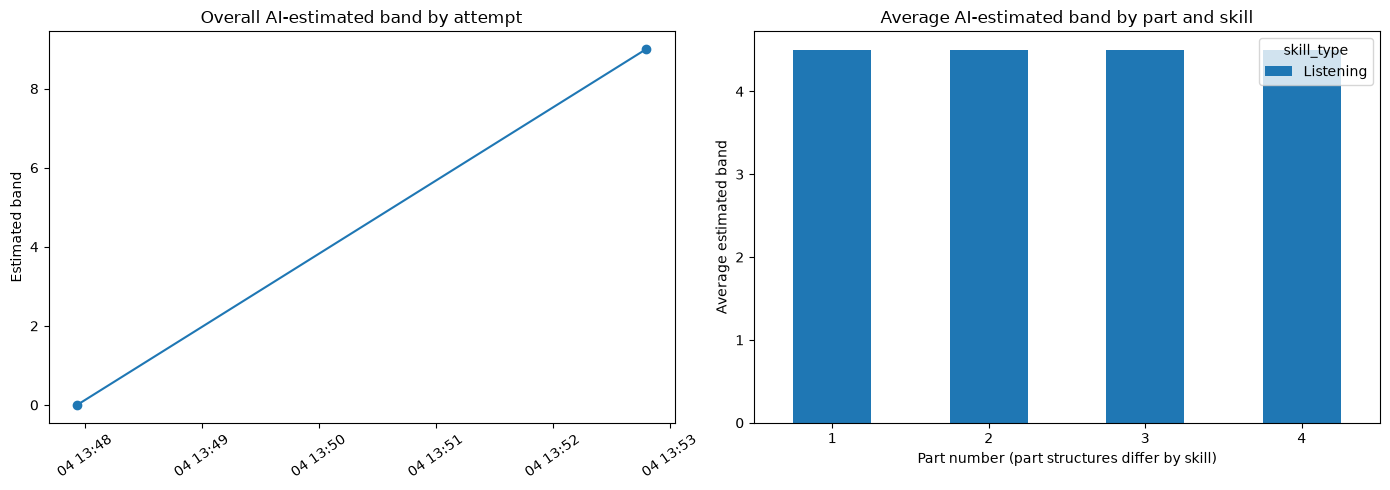

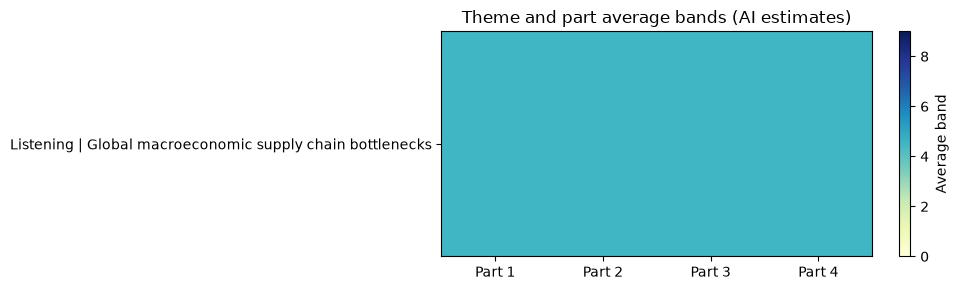

In [11]:
if attempts_df.empty and parts_df.empty:
    print('Charts will appear after attempts and part scores have been saved.')
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    if not attempts_df.empty:
        attempts_plot = attempts_df.copy()
        attempts_plot['timestamp'] = pd.to_datetime(attempts_plot['timestamp'], errors='coerce')
        attempts_plot = attempts_plot.dropna(subset=['timestamp']).sort_values('timestamp')
        axes[0].plot(attempts_plot['timestamp'], attempts_plot['graded_band'], marker='o')
        axes[0].set_title('Overall AI-estimated band by attempt')
        axes[0].set_ylabel('Estimated band')
        axes[0].tick_params(axis='x', rotation=35)
    else:
        axes[0].set_visible(False)
    if not parts_df.empty:
        averages = parts_df.groupby(['skill_type', 'part_number'])['band_score'].mean().unstack(0)
        averages.plot(kind='bar', ax=axes[1])
        axes[1].set_title('Average AI-estimated band by part and skill')
        axes[1].set_xlabel('Part number (part structures differ by skill)')
        axes[1].set_ylabel('Average estimated band')
        axes[1].tick_params(axis='x', rotation=0)
    else:
        axes[1].set_visible(False)
    fig.tight_layout()
    plt.show()

if not parts_df.empty:
    theme_part = parts_df.pivot_table(index=['skill_type', 'theme'], columns='part_number', values='band_score', aggfunc='mean')
    if not theme_part.empty:
        fig, ax = plt.subplots(figsize=(10, max(3, 0.5 * len(theme_part))))
        image = ax.imshow(theme_part.to_numpy(dtype=float), aspect='auto', cmap='YlGnBu', vmin=0, vmax=9)
        ax.set_yticks(range(len(theme_part.index)))
        ax.set_yticklabels([f'{skill} | {theme}' for skill, theme in theme_part.index])
        ax.set_xticks(range(len(theme_part.columns)))
        ax.set_xticklabels([f'Part {part}' for part in theme_part.columns])
        ax.set_title('Theme and part average bands (AI estimates)')
        fig.colorbar(image, ax=ax, label='Average band')
        fig.tight_layout()
        plt.show()

if not criteria_df.empty:
    criteria_plot = criteria_df.dropna(subset=['band_score']).copy()
    if not criteria_plot.empty:
        criteria_plot['skill_theme_part'] = criteria_plot.apply(
            lambda row: f"{row['skill_type']} | {row['theme']} | P{row['part_number']}", axis=1
        )
        criteria_matrix = criteria_plot.pivot_table(
            index='skill_theme_part', columns='criterion_name', values='band_score', aggfunc='mean'
        )
        fig, ax = plt.subplots(figsize=(12, max(3, 0.45 * len(criteria_matrix))))
        image = ax.imshow(criteria_matrix.to_numpy(dtype=float), aspect='auto', cmap='YlOrRd_r', vmin=0, vmax=9)
        ax.set_yticks(range(len(criteria_matrix.index)))
        ax.set_yticklabels(criteria_matrix.index)
        ax.set_xticks(range(len(criteria_matrix.columns)))
        ax.set_xticklabels(criteria_matrix.columns, rotation=30, ha='right')
        ax.set_title('Average rubric criterion scores (AI practice estimates)')
        fig.colorbar(image, ax=ax, label='Average band')
        fig.tight_layout()
        plt.show()

if not quality_df.empty:
    quality_plot = quality_df.dropna(subset=['target_band', 'estimated_band']).copy()
    if not quality_plot.empty:
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.scatter(quality_plot['target_band'], quality_plot['estimated_band'], c=quality_plot['difficulty_fit'], cmap='viridis', vmin=0, vmax=1)
        ax.plot([4, 9], [4, 9], linestyle='--', color='gray')
        ax.set(xlim=(4, 9), ylim=(4, 9), xlabel='Requested target band', ylabel='QA-estimated difficulty', title='Generation difficulty QA (model estimate)')
        fig.colorbar(ax.collections[0], ax=ax, label='Difficulty fit')
        fig.tight_layout()
        plt.show()

In [12]:
STOPWORDS = {'a', 'about', 'above', 'after', 'again', 'all', 'also', 'am', 'an', 'and', 'any', 'are', 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'could', 'did', 'do', 'does', 'doing', 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'has', 'have', 'having', 'he', 'her', 'here', 'hers', 'him', 'his', 'how', 'i', 'if', 'in', 'into', 'is', 'it', 'its', 'just', 'me', 'more', 'most', 'my', 'no', 'nor', 'not', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'out', 'over', 'own', 'same', 'she', 'should', 'so', 'some', 'such', 'than', 'that', 'the', 'their', 'them', 'then', 'there', 'these', 'they', 'this', 'those', 'through', 'to', 'too', 'under', 'until', 'up', 'very', 'was', 'we', 'were', 'what', 'when', 'where', 'which', 'while', 'who', 'with', 'would', 'you', 'your'}
ASPECT_TERMS = {
    'task_response': {'task', 'prompt', 'requirement', 'relevant', 'respond', 'response', 'complete', 'address'},
    'coherence': {'coherence', 'cohesion', 'organize', 'organized', 'structure', 'paragraph', 'transition'},
    'vocabulary': {'vocabulary', 'lexical', 'word', 'words', 'range', 'collocation', 'phrase'},
    'grammar': {'grammar', 'grammatical', 'tense', 'sentence', 'sentences', 'article', 'agreement', 'punctuation'},
    'listening_reading_accuracy': {'accuracy', 'accurate', 'incorrect', 'answer', 'answers', 'spelling', 'detail', 'details'},
}

def tokenize(text):
    return [word for word in re.findall(r"[a-zA-Z']+", str(text).lower()) if len(word) > 2 and word not in STOPWORDS]

if parts_df.empty:
    print('No evaluator feedback is available yet.')
else:
    aspect_rows = []
    for column, polarity in [('strengths', 'strength'), ('weaknesses', 'weakness')]:
        tokens = [token for value in parts_df[column].dropna() for token in tokenize(value)]
        print(f'Most common {polarity} terms (exploratory, not calibrated):')
        display(pd.DataFrame(Counter(tokens).most_common(15), columns=['term', 'count']))
        for text in parts_df[column].dropna():
            text_tokens = set(tokenize(text))
            for aspect, terms in ASPECT_TERMS.items():
                matches = text_tokens & terms
                if matches:
                    aspect_rows.append({'polarity': polarity, 'aspect': aspect, 'matched_terms': ', '.join(sorted(matches))})
    aspect_counts = pd.DataFrame(aspect_rows)
    if aspect_counts.empty:
        print('No aspect keywords matched. Consider expanding the transparent keyword lists for your feedback language.')
    else:
        print('Feedback mentions by aspect (keyword counts; not IELTS criterion scores):')
        display(aspect_counts.groupby(['polarity', 'aspect']).size().rename('mentions').reset_index())

Most common strength terms (exploratory, not calibrated):


,term,count
0,academic,4
1,questions,3
2,received,3
3,accurate,2
4,flawless,2
5,spelling,2
6,word,2
7,limit,2
8,test,1
9,materials,1


Most common weakness terms (exploratory, not calibrated):


,term,count
0,questions,6
1,correct,4
2,submitted,3
3,answers,2
4,left,2
5,multiple,2
6,choice,2
7,matching,2
8,responses,2
9,form,1


Feedback mentions by aspect (keyword counts; not IELTS criterion scores):


,polarity,aspect,mentions
0,strength,grammar,1
1,strength,listening_reading_accuracy,3
2,strength,vocabulary,2
3,weakness,listening_reading_accuracy,2
4,weakness,vocabulary,1


## Optional predictive baselines

The per-part baseline predicts the AI grader's per-part band and therefore learns AI estimates, not ground truth. The criterion-level model is separate: it uses the learner's response text plus skill, theme, part, criterion, and target band, and trains only against human-reviewed criterion ratings. Both splits group by submission to prevent attempt leakage. A minimum of 30 distinct attempts across 3 themes is only a preliminary experiment gate, not a guarantee of scientific reliability.

If scikit-learn is missing, install it in this notebook kernel with `%pip install scikit-learn`.

In [13]:
MIN_DISTINCT_ATTEMPTS = 30
MIN_THEMES = 3
distinct_attempts = parts_df['submission_id'].nunique() if not parts_df.empty else 0
theme_count = parts_df['theme'].nunique() if not parts_df.empty else 0

if parts_df.empty or distinct_attempts < MIN_DISTINCT_ATTEMPTS or theme_count < MIN_THEMES:
    print(f'ML training skipped: found {distinct_attempts} distinct attempts and {theme_count} themes.')
    print(f'For this preliminary baseline, collect at least {MIN_DISTINCT_ATTEMPTS} attempts across {MIN_THEMES} themes; collect more before trusting results.')
else:
    try:
        from sklearn.compose import ColumnTransformer
        from sklearn.ensemble import RandomForestRegressor
        from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
        from sklearn.model_selection import GroupShuffleSplit
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import OneHotEncoder
    except ImportError as exc:
        raise ImportError('Install scikit-learn in this notebook kernel with `%pip install scikit-learn`.') from exc

    model_data = parts_df.dropna(subset=['submission_id', 'skill_type', 'theme', 'part_number', 'target_band', 'band_score']).copy()
    features = ['skill_type', 'theme', 'part_number', 'target_band']
    target = 'band_score'
    group_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_index, test_index = next(group_split.split(model_data[features], model_data[target], groups=model_data['submission_id']))
    train_data, test_data = model_data.iloc[train_index], model_data.iloc[test_index]

    categorical = ['skill_type', 'theme', 'part_number']
    numeric = ['target_band']
    preprocess = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('numeric', 'passthrough', numeric),
    ])
    model = Pipeline([
        ('preprocess', preprocess),
        ('regressor', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)),
    ])
    model.fit(train_data[features], train_data[target])
    predictions = model.predict(test_data[features])
    rmse = mean_squared_error(test_data[target], predictions) ** 0.5
    print(f'Train attempts: {train_data["submission_id"].nunique()}; test attempts: {test_data["submission_id"].nunique()}')
    print(f'Test MAE: {mean_absolute_error(test_data[target], predictions):.3f} bands')
    print(f'Test RMSE: {rmse:.3f} bands')
    print(f'Test RÂ²: {r2_score(test_data[target], predictions):.3f}')
    print('Interpretation: these metrics measure agreement with historical AI estimates, not official IELTS performance.')
    display(test_data[['submission_id', 'skill_type', 'theme', 'part_number', target]].assign(predicted_band=predictions).head(20))

ML training skipped: found 2 distinct attempts and 1 themes.
For this preliminary baseline, collect at least 30 attempts across 3 themes; collect more before trusting results.


In [18]:
MIN_CRITERION_ATTEMPTS = 30
MIN_CRITERION_THEMES = 3
if human_ratings_df.empty:
    human_model_data = pd.DataFrame()
else:
    human_model_data = (human_ratings_df.dropna(subset=['band_score'])
                        .groupby(['submission_id', 'test_id', 'part_number', 'criterion_name', 'skill_type', 'theme', 'target_band'], as_index=False)
                        .agg(band_score=('band_score', 'mean'),
                             candidate_response=('candidate_response', 'first'),
                             reviewer_count=('rating_id', 'nunique')))
    human_model_data['candidate_response'] = human_model_data['candidate_response'].fillna('').astype(str)
    human_model_data = human_model_data[human_model_data['candidate_response'].str.strip().ne('')]

criterion_attempts = human_model_data['submission_id'].nunique() if not human_model_data.empty else 0
criterion_themes = human_model_data['theme'].nunique() if not human_model_data.empty else 0

if human_model_data.empty or criterion_attempts < MIN_CRITERION_ATTEMPTS or criterion_themes < MIN_CRITERION_THEMES:
    print(f'Human-label ML skipped: found {criterion_attempts} distinct attempts and {criterion_themes} themes with reviewed criterion scores and responses.')
    print(f'Collect at least {MIN_CRITERION_ATTEMPTS} distinct attempts across {MIN_CRITERION_THEMES} themes before this preliminary experiment.')
else:
    try:
        from sklearn.compose import ColumnTransformer
        from sklearn.ensemble import RandomForestRegressor
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.metrics import mean_absolute_error, mean_squared_error
        from sklearn.model_selection import GroupShuffleSplit
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import OneHotEncoder
    except ImportError as exc:
        raise ImportError('Install scikit-learn in this notebook kernel with `%pip install scikit-learn`.') from exc

    criterion_features = ['candidate_response', 'skill_type', 'theme', 'part_number', 'criterion_name', 'target_band']
    criterion_target = 'band_score'
    split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_idx, test_idx = next(split.split(
        human_model_data[criterion_features],
        human_model_data[criterion_target],
        groups=human_model_data['submission_id'],
    ))
    criterion_train = human_model_data.iloc[train_idx]
    criterion_test = human_model_data.iloc[test_idx]
    categorical = ['skill_type', 'theme', 'part_number', 'criterion_name']
    preprocessing = ColumnTransformer([
        ('response_text', TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=2000), 'candidate_response'),
        ('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('numeric', 'passthrough', ['target_band']),
    ])
    criterion_model = Pipeline([
        ('preprocess', preprocessing),
        ('regressor', RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)),
    ])
    criterion_model.fit(criterion_train[criterion_features], criterion_train[criterion_target])
    criterion_predictions = criterion_model.predict(criterion_test[criterion_features])
    criterion_rmse = mean_squared_error(criterion_test[criterion_target], criterion_predictions) ** 0.5
    print(f'Train attempts: {criterion_train["submission_id"].nunique()}; test attempts: {criterion_test["submission_id"].nunique()}')
    print(f'Human-label test MAE: {mean_absolute_error(criterion_test[criterion_target], criterion_predictions):.3f} bands')
    print(f'Human-label test RMSE: {criterion_rmse:.3f} bands')
    print('These metrics are evaluated against human-reviewed labels, grouped by attempt to prevent leakage.')
    display(criterion_test[['submission_id', 'skill_type', 'theme', 'part_number', 'criterion_name', 'band_score', 'reviewer_count']].assign(predicted_band=criterion_predictions).head(20))

Human-label ML skipped: found 0 distinct attempts and 0 themes with reviewed criterion scores and responses.
Collect at least 30 distinct attempts across 3 themes before this preliminary experiment.


## Improve the data before trusting a model

1. Save structured AI scores and evidence for relevant assessment dimensions, with AI estimates clearly distinguished from human ratings.
2. Use the Analytics review form to collect human-reviewed criterion labels and reviewer provenance; do not infer pronunciation from typed Speaking answers.
3. Collect many attempts across repeated themes and skills, and retain submission IDs so validation splits keep whole attempts together.
4. Compare against a simple baseline, report uncertainty, and evaluate only against human-reviewed labels before using predictions for decisions.
5. Keep this notebook's SQLite connection read-only. The models are exploratory and are not official examiners.